# Homework 4: Color and Accuracy
## Name: Jon Knapp
### Date: November 12, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

_Two sentences, written once the analysis is done: what I used AI tools for, and how I verified the output (items 9 and 10, measuring the same quantity on three charts, are the model the assignment gives for that verification)._

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

## Setup

The captures were made in class: twelve raw files, three ColorChecker charts and one photograph of the white sheet in each of three rounds (one round per illuminant). This assignment produces the five color entries of the Project 1 `results.json`, so do the measurement before submitting Project 1.

Before running past item 1:
* Put each round's DNGs in its own folder under `Homework 4 Image Captures/` and enter the file names in `CAPTURES` below. Keep chart A, B and C tied to the same physical chart in every round: nothing in the images can recover that correspondence later (item 9).
* A round that came back as HEIC or JPEG cannot be used in Parts 1 to 3 (the phone has already applied its own white balance and color matrix). Item 1 flags it; say which round it was and work with the rest.
* After item 2, read the four outer corners of the patch grid off each chart image and enter them in `CHART_CORNERS` (item 4 explains the order).

Folders:
* `Homework 4 Image Captures/<round>/`: the three charts and the white sheet for that round

In [1]:
# If rawpy, tifffile or colour-science isn't installed:  %pip install rawpy tifffile colour-science
import json
from itertools import combinations
from pathlib import Path

import colour
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import tifffile
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon

# --- Captures -----------------------------------------------------------------
CAPTURE_ROOT = Path("Homework 4 Image Captures")

# One entry per round (illuminant). Rename the keys and folders to match the lights used in class:
# two rounds share a color temperature but differ in spectrum (a smooth blackbody lamp and an LED
# with a blue peak and phosphor hump); the third has a different color temperature and a smooth
# spectrum (the outdoor round).
ROUND_DIRS = {
    "blackbody": CAPTURE_ROOT / "Blackbody",
    "led":       CAPTURE_ROOT / "LED",
    "outdoor":   CAPTURE_ROOT / "Outdoor",
}
# File names inside each round's folder. None = not entered yet.
# Every round was shot in the order chart A, chart B, chart C, white sheet (EXIF timestamps,
# 20 Oct 2026); the Outdoor files were IMG_0941-IMG_0944 in that order.
CAPTURES = {
    "blackbody": {"chart A": "chart A.DNG", "chart B": "chart B.DNG", "chart C": "chart C.DNG", "white": "white.DNG"},
    "led":       {"chart A": "chart A.DNG", "chart B": "chart B.DNG", "chart C": "chart C.DNG", "white": "white.DNG"},
    "outdoor":   {"chart A": "chart A.DNG", "chart B": "chart B.DNG", "chart C": "chart C.DNG", "white": "white.DNG"},
}
CHARTS = ("chart A", "chart B", "chart C")
ROUNDS = tuple(ROUND_DIRS)

# --- Which captures each part uses ---------------------------------------------
# LED is the primary round because it has no clipped patches; the blackbody round clips patch 19
# (white) and patch 16 (yellow) on every chart, and neutrals 20-21 partly on chart C.
PRIMARY_ROUND = "led"             # items 2-8: one capture, and the illuminant the matrix is fitted under
PRIMARY_CHART = "chart A"
PART3_ROUND = PRIMARY_ROUND       # item 9: the illuminant whose three charts are compared
TRANSFER_ROUNDS = ("blackbody", "outdoor")   # items 11 and 12, in that order

# --- Item 1: saturation -------------------------------------------------------
SAT_WINDOW_DN = 400       # look only at the top this many DN below each file's maximum
SAT_TOL_DN = 2            # values within this of the ceiling count as "at" it
SPIKE_FACTOR = 8          # a clipping spike: the top value holds this many times the typical count per occupied value
SPIKE_MIN_PIXELS = 100    # ...and at least this many pixels (rules out a handful of hot pixels)
SAT_OVERRIDE_DN = None    # set a number to override the measured saturation value

# --- Item 3: flat field -------------------------------------------------------
# Which round's white sheet corrects each round. Item 3 decides whether one round's flat can
# stand in for another's (e.g. {"outdoor": "blackbody"} if the outdoor sheet is blown out).
# The blackbody white sheet is clipped at its center (lamp hot spot), so that round borrows the LED
# flat field. Item 3 has to confirm the falloff belongs to the lens (same profile in every round).
FLAT_SOURCE = {"blackbody": "led", "led": "led", "outdoor": "outdoor"}
FLAT_SMOOTH = 0.01        # Gaussian sigma for the flat field, as a fraction of the image width
REGION_FRAC = 0.05        # side of the center/corner regions, as a fraction of the shorter image side
CORNER_INSET = 0.02       # keep the corner regions this far (fraction of each side) from the frame edge

# --- Item 4: patch locations ----------------------------------------------------
# Outer corners of the 6 x 4 patch grid, in quarter-resolution pixels (x, y), in this order:
#   [corner by patch 1 (dark skin), corner by patch 6 (bluish green),
#    corner by patch 24 (black),     corner by patch 19 (white)]
# The order follows the chart, not the image, so a rotated chart is handled correctly.
CHART_CORNERS = {(r, c): None for r in ROUNDS for c in CHARTS}
SAMPLE_FRACTION = 0.40    # sampled square, as a fraction of the patch pitch (the middle half of a patch or less)

# --- Part 2 -------------------------------------------------------------------
REFERENCE_SET = "ColorChecker24 - After November 2014"
GAIN_PATCH = 22           # white balance from neutral 5 (mid gray), never from white
WHITE_PATCH = 19          # reference neutral for CIELAB; falls back to the brightest unclipped neutral
DE_METHOD = "CIE 2000"    # colour.delta_E method; the name is printed wherever a ΔE is quoted
LAB_WHITE = "reference"   # "reference": both Labs use the published XYZ of the reference neutral as white
                          #   (measurement scaled so that neutral's Y matches its published Y);
                          # "own": the measured Lab uses the measured XYZ of that same patch as its white
RESULTS_FILE = Path("hw4_color_results.json")

In [2]:
# --- lens_id helper, as given on the Project 1 page ---------------------------
def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None


def _num(v):
    """EXIF rationals arrive as (numerator, denominator) tuples."""
    if isinstance(v, (tuple, list)):
        return v[0] / v[1] if len(v) == 2 else float(v[0])
    return None if v is None else float(v)


def camera_exif(path):
    """ISO and exposure time as plain numbers."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings") or _lookup(p, "PhotographicSensitivity")
        return {"ISO": int(iso[0] if isinstance(iso, (tuple, list)) else iso) if iso else None,
                "exposure_s": _num(_lookup(p, "ExposureTime"))}


def fmt_exposure(s):
    return "?" if s is None else (f"{s:g} s" if s >= 1 else f"1/{1 / s:.4g} s")


def srgb_encode(x):
    """Piecewise sRGB transfer function, linear [0, 1] -> encoded [0, 1]."""
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.power(x, 1 / 2.4) - 0.055)


# --- Captures -----------------------------------------------------------------
def capture_path(rnd, item):
    name = CAPTURES[rnd][item]
    return None if name is None else ROUND_DIRS[rnd] / name


def have(rnd, item):
    p = capture_path(rnd, item)
    return p is not None and p.is_file()


def missing(*keys):
    """Message naming the (round, item) captures that are not available, or '' if all are."""
    gone = [f"{r} / {i}" for r, i in keys if not have(r, i)]
    return ("Missing captures (fill in CAPTURES and the folders): " + ", ".join(gone)) if gone else ""


_RAW = {}
def read_raw(path):
    """Bayer mosaic, CFA order, per-site black level and declared white level. Cached."""
    key = str(path)
    if key not in _RAW:
        with rawpy.imread(key) as r:
            if r.raw_pattern is None or r.raw_image_visible.ndim != 2:
                raise ValueError(f"{Path(path).name} is not a Bayer mosaic (ProRAW / LinearRaw?)")
            pattern = r.raw_pattern.copy()
            desc = r.color_desc.decode()                  # e.g. "RGBG": index 3 is the second green
            _RAW[key] = {
                "mosaic": r.raw_image_visible.copy(),
                "cfa": "".join(desc[pattern[i, j]] for i in range(2) for j in range(2)),
                "black": np.array([[r.black_level_per_channel[pattern[i, j]] for j in range(2)]
                                   for i in range(2)], dtype=float),
                "white_level": float(r.white_level),
            }
    return _RAW[key]


def quarter_res(raw, sat_dn):
    """Black-subtracted, saturation-normalized quarter-resolution RGB, without demosaicing:
    the red site, the mean of the two green sites and the blue site of each 2x2 tile.
    Also returns a mask of tiles in which any site reached the saturation value."""
    m = raw["mosaic"].astype(np.float64)
    h, w = (s // 2 * 2 for s in m.shape)
    sites = {"R": [], "G": [], "B": []}
    clipped = np.zeros((h // 2, w // 2), bool)
    for i in range(2):
        for j in range(2):
            site = m[i:h:2, j:w:2]
            clipped |= site >= sat_dn - SAT_TOL_DN
            black = raw["black"][i, j]
            sites[raw["cfa"][2 * i + j]].append((site - black) / (sat_dn - black))
    assert [len(sites[c]) for c in "RGB"] == [1, 2, 1], f"Unexpected CFA {raw['cfa']}"
    rgb = np.dstack([sites["R"][0], 0.5 * (sites["G"][0] + sites["G"][1]), sites["B"][0]])
    return rgb.astype(np.float32), clipped


def box_mean(img, x0, y0, side):
    return img[y0:y0 + side, x0:x0 + side].reshape(-1, img.shape[-1]).mean(axis=0)


def region_means(img, frac=REGION_FRAC, inset=CORNER_INSET):
    """Per-channel means of a center region and the four corner regions (same size)."""
    h, w = img.shape[:2]
    s = int(frac * min(h, w))
    ix, iy = int(inset * w), int(inset * h)
    return {"center": box_mean(img, (w - s) // 2, (h - s) // 2, s),
            "top left": box_mean(img, ix, iy, s), "top right": box_mean(img, w - ix - s, iy, s),
            "bottom left": box_mean(img, ix, h - iy - s, s),
            "bottom right": box_mean(img, w - ix - s, h - iy - s, s)}


def show_linear(ax, rgb, scale, title="", step=2):
    """Display linear RGB: divide by `scale` (per channel), sRGB-encode, show every `step`th pixel."""
    ax.imshow(srgb_encode(rgb[::step, ::step] / np.asarray(scale)),
              extent=(-0.5, rgb.shape[1] - 0.5, rgb.shape[0] - 0.5, -0.5))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

## Part 1: From Raw File to Patch Values
### Problem 1: Inventory your captures and confirm that every one of them is a Bayer raw file from the same camera, and that the ISO and exposure time are identical within each round. Then check every frame for clipping, which is the one defect that cannot be repaired afterwards. Do not take the white level recorded in the file on trust: histogram the raw values and look for a spike at the top of the range. Look only at the very top of the histogram. Any clipped patch has to be excluded from everything that follows, and the outdoor round is where you are most likely to find one.
_Deliverable: A list of your files with the round, chart, ISO, and exposure time of each, the lens_id assertion from the Project 1 page passing across all of them, the raw value at which your files actually saturate, and the fraction of each frame that reaches it._

In [3]:
inventory = []
for rnd in ROUNDS:
    for item in (*CHARTS, "white"):
        p = capture_path(rnd, item)
        row = {"round": rnd, "item": item, "file": None if p is None else p.name,
               "ISO": None, "exposure": None, "bayer_raw": False, "lens_id": None, "note": ""}
        if p is None or not p.is_file():
            row["note"] = "not entered" if p is None else "file not found"
        elif p.suffix.lower() != ".dng":
            row["note"] = f"{p.suffix} is not raw: the phone's own white balance and matrix are baked in"
        else:
            try:
                ex = camera_exif(p)
                row.update(ISO=ex["ISO"], exposure=fmt_exposure(ex["exposure_s"]), lens_id=lens_id(p))
                read_raw(p)
                row["bayer_raw"] = True
            except Exception as e:
                row["note"] = f"{type(e).__name__}: {e}"
        inventory.append(row)
inventory = pd.DataFrame(inventory)
display(inventory.drop(columns="lens_id").style.hide(axis="index"))

usable = inventory[inventory.bayer_raw]
if usable.empty:
    print("No usable raw captures yet: fill in CAPTURES above.")
else:
    ids = set(usable.lens_id)
    assert len(ids) == 1, f"Captures came from {len(ids)} cameras: {ids}"
    print(f"lens_id assertion passed for all {len(usable)} raw captures: {next(iter(ids))}")
    for rnd, g in usable.groupby("round", sort=False):
        same = g.ISO.nunique() == 1 and g.exposure.nunique() == 1
        print(f"  {rnd}: ISO {sorted(g.ISO.unique())}, exposure {sorted(g.exposure.unique())}"
              + ("" if same else "   ! not identical within the round"))

round,item,file,ISO,exposure,bayer_raw,note
blackbody,chart A,chart A.DNG,400,1/60 s,True,
blackbody,chart B,chart B.DNG,400,1/60 s,True,
blackbody,chart C,chart C.DNG,400,1/60 s,True,
blackbody,white,white.DNG,400,1/60 s,True,
led,chart A,chart A.DNG,400,1/60 s,True,
led,chart B,chart B.DNG,400,1/60 s,True,
led,chart C,chart C.DNG,400,1/60 s,True,
led,white,white.DNG,400,1/60 s,True,
outdoor,chart A,chart A.DNG,400,1/250 s,True,
outdoor,chart B,chart B.DNG,400,1/250 s,True,


lens_id assertion passed for all 12 raw captures: ('iPhone 16 Pro Max back camera 6.765mm f/1.78', 6.765, 24, (4032, 3024))
  blackbody: ISO [400], exposure ['1/60 s']
  led: ISO [400], exposure ['1/60 s']
  outdoor: ISO [400], exposure ['1/250 s']


Saturation value: 4095 DN (measured from the clipping spike in 4 file(s)); declared white level 4095 DN


round,item,max DN,declared white,pixels at max,spike ratio,spike at top,fraction at saturation,reaches saturation
blackbody,chart A,4095,4095,15978,42.2,True,1.79e-03,True
blackbody,chart B,4095,4095,16424,111.7,True,1.85e-03,True
blackbody,chart C,4095,4095,22294,229.8,True,2.33e-03,True
blackbody,white,4095,4095,134737,48.1,True,1.86e-02,True
led,chart A,1516,4095,1,0.0,False,0.00e+00,False
led,chart B,1694,4095,2,0.0,False,0.00e+00,False
led,chart C,1729,4095,1,0.0,False,0.00e+00,False
led,white,1846,4095,1,0.0,False,0.00e+00,False
outdoor,chart A,1447,4095,1,0.0,False,0.00e+00,False
outdoor,chart B,1495,4095,1,0.0,False,0.00e+00,False


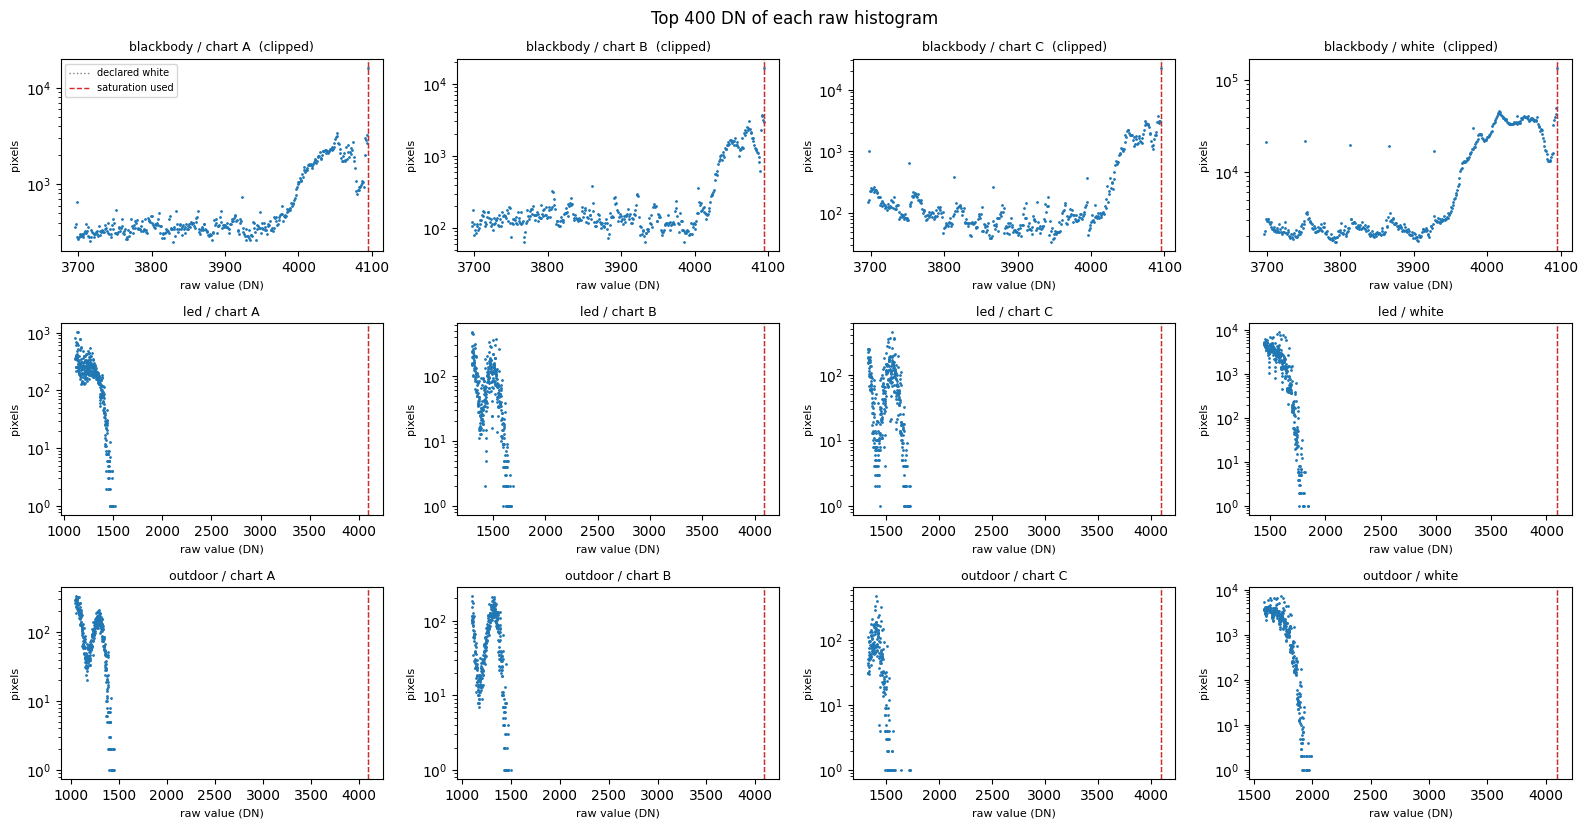

In [4]:
def top_of_range(mosaic):
    """Histogram of the top SAT_WINDOW_DN of a raw mosaic, and whether it ends in a clipping spike."""
    v = mosaic.ravel()
    vmax = int(v.max())
    vals, counts = np.unique(v[v > vmax - SAT_WINDOW_DN], return_counts=True)
    at_max = int(counts[-1])                                        # pixels at exactly the top value
    below = counts[vals < vmax - SAT_TOL_DN]
    baseline = float(np.median(below)) if below.size else 0.0      # typical count per occupied value
    ratio = at_max / max(baseline, 1.0)
    spike = at_max >= SPIKE_MIN_PIXELS and ratio > SPIKE_FACTOR
    return {"max_DN": vmax, "pixels_at_max": at_max, "typical_count": baseline, "spike_ratio": ratio, "spike": spike,
            "vals": vals, "counts": counts}


if usable.empty:
    print("No usable raw captures yet.")
else:
    tops = {}
    for row in usable.itertuples():
        raw = read_raw(capture_path(row.round, row.item))
        tops[(row.round, row.item)] = dict(top_of_range(raw["mosaic"]), white_level=raw["white_level"])

    ceilings = [t["max_DN"] for t in tops.values() if t["spike"]]
    declared = min(t["white_level"] for t in tops.values())
    if SAT_OVERRIDE_DN is not None:
        SAT_DN, how = float(SAT_OVERRIDE_DN), "set by hand (SAT_OVERRIDE_DN)"
    elif ceilings:
        SAT_DN, how = float(min(ceilings)), f"measured from the clipping spike in {len(ceilings)} file(s)"
    else:
        SAT_DN, how = declared, "no file reaches a ceiling, so the declared white level is used"
    print(f"Saturation value: {SAT_DN:.0f} DN ({how}); declared white level {declared:.0f} DN")

    sat_table = pd.DataFrame([{
        "round": r, "item": i, "max DN": t["max_DN"], "declared white": t["white_level"],
        "pixels at max": t["pixels_at_max"], "spike ratio": t["spike_ratio"], "spike at top": t["spike"],
        "fraction at saturation": float(np.mean(read_raw(capture_path(r, i))["mosaic"] >= SAT_DN - SAT_TOL_DN)),
    } for (r, i), t in tops.items()])
    sat_table["reaches saturation"] = sat_table["fraction at saturation"] > 0
    display(sat_table.style.hide(axis="index").format({"fraction at saturation": "{:.2e}", "spike ratio": "{:.1f}",
                                                       "declared white": "{:.0f}"}))

    n = len(tops)
    ncols = min(4, n)
    fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, figsize=(4 * ncols, 2.8 * int(np.ceil(n / ncols))),
                             squeeze=False)
    for ax, ((r, i), t) in zip(axes.flat, tops.items()):
        ax.semilogy(t["vals"], t["counts"], ".", ms=2)
        ax.axvline(t["white_level"], color="gray", ls=":", lw=1, label="declared white")
        ax.axvline(SAT_DN, color="tab:red", ls="--", lw=1, label="saturation used")
        ax.set_title(f"{r} / {i}" + ("  (clipped)" if t["spike"] else ""), fontsize=9)
        ax.set_xlabel("raw value (DN)", fontsize=8); ax.set_ylabel("pixels", fontsize=8)
    for ax in axes.flat[n:]:
        ax.axis("off")
    axes.flat[0].legend(fontsize=7)
    fig.suptitle(f"Top {SAT_WINDOW_DN} DN of each raw histogram")
    fig.tight_layout()
    plt.show()

### **What do my captures look like?**
**Inventory:** All twelve captures are Bayer raw DNGs (BGGR mosaic) from the same camera, the iPhone 16 Pro Max main camera (6.765 mm, f/1.78), so the lens_id assertion passes for every file. None of the rounds came back as HEIC or JPEG. ISO and exposure time are identical within each round: ISO 400 at 1/60 s for the blackbody and LED rounds, and ISO 400 at 1/250 s for the outdoor round.

**How to read the histograms:** Each panel covers only the top 400 DN below that file's brightest pixel. The x-axis is the raw value, and the y-axis (log scale) is how many pixels have that value. The red dashed line is the saturation value I used (4095 DN), and it hides the gray dotted line for the declared white level, which is also 4095 DN. A clipped file piles pixels up against that ceiling, so its histogram ends in a tall spike at the right edge. An unclipped file's histogram instead tails off to one or two pixels well below the line.

**Saturation value: 4095 DN.** The blackbody files pile up at exactly 4095 DN, the same value as the declared white level, so these files saturate at their declared level rather than below it. The isolated dots near 2 × 10⁴ pixels at the left of the blackbody white-sheet panel are the coarse quantization at high signal that the assignment warns about, not clipping. They are why the search looks only at the very top of the range.

**Which frames clip:**
* **Blackbody round, all four frames:** 0.18%, 0.19% and 0.23% of the frame for charts A, B and C (15,978–22,294 pixels at 4095 DN, 42–230 times the typical count per value just below it), and 1.86% for the white sheet. On the charts, the clipped pixels are on patch 19 (white) and patch 16 (yellow) of every chart, on part of patches 20 and 21 (neutral 8 and neutral 6.5) of chart C, and on a few pixels of patch 11 (yellow green) of chart A. The white sheet is blown out at its center, where the lamp's hot spot falls.
* **LED and outdoor rounds:** no frame comes near the ceiling. Their brightest pixels reach only 1,447–1,986 DN, 26–41% of the span from the 528 DN black level to saturation.

**What this means for the rest of the assignment:** The clipped blackbody patches are excluded from everything that follows. The LED round is therefore my primary round for Parts 2 and 3. It has no clipped patches, and none of its patches touch the gain patch (patch 22, neutral 5), which is unclipped in every round. The blackbody white sheet cannot serve as its own flat field, so the blackbody round borrows the LED flat field in item 3.

### Problem 2: Convert one capture to linear color without demosaicing it. Subtract the black level, divide by the span from black up to the saturation value you measured in item 1, and then take each 2 by 2 block of the mosaic to one pixel of a quarter resolution image, using the red site, the mean of the two green sites, and the blue site. Read the mosaic order from the file rather than assuming it is RGGB.
_Deliverable: The quarter resolution image displayed, and a statement of the CFA pattern, the black level, and the saturation value you used._

chart A.DNG (led / chart A)
  CFA pattern (read from the file): BGGR
  black level per site [[top-left, top-right], [bottom-left, bottom-right]]: [[528.0, 528.0], [528.0, 528.0]] DN
  saturation value (item 1): 4095 DN
  quarter-resolution image: 2016 x 1512 px; 0.00e+00 of its pixels touch saturation


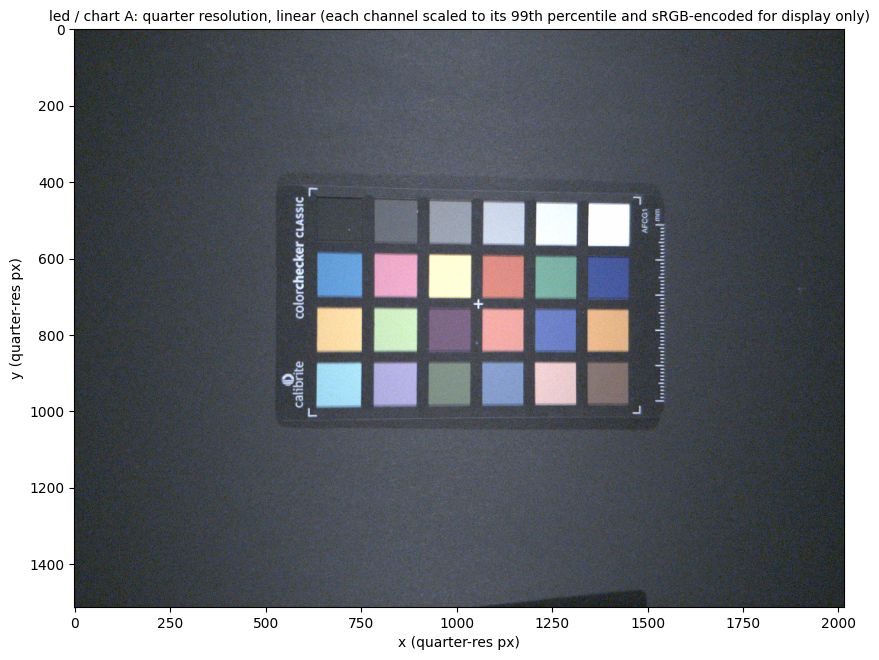

In [5]:
if (msg := missing((PRIMARY_ROUND, PRIMARY_CHART))):
    print(msg)
else:
    raw0 = read_raw(capture_path(PRIMARY_ROUND, PRIMARY_CHART))
    rgb0, clip0 = quarter_res(raw0, SAT_DN)
    print(f"{capture_path(PRIMARY_ROUND, PRIMARY_CHART).name} ({PRIMARY_ROUND} / {PRIMARY_CHART})")
    print(f"  CFA pattern (read from the file): {raw0['cfa']}")
    print(f"  black level per site [[top-left, top-right], [bottom-left, bottom-right]]: {raw0['black'].tolist()} DN")
    print(f"  saturation value (item 1): {SAT_DN:.0f} DN")
    print(f"  quarter-resolution image: {rgb0.shape[1]} x {rgb0.shape[0]} px; "
          f"{clip0.mean():.2e} of its pixels touch saturation")

    fig, ax = plt.subplots(figsize=(10, 7.5))
    show_linear(ax, rgb0, np.percentile(rgb0, 99, axis=(0, 1)),
                f"{PRIMARY_ROUND} / {PRIMARY_CHART}: quarter resolution, linear "
                "(each channel scaled to its 99th percentile and sRGB-encoded for display only)")
    ax.axis("on")
    ax.set_xlabel("x (quarter-res px)"); ax.set_ylabel("y (quarter-res px)")
    plt.show()

### **Which CFA pattern, black level and saturation value did I use?**
I converted the LED round's chart A (`chart A.DNG`) to a 2016 × 1512 px quarter-resolution image. None of its pixels touch saturation.

**CFA pattern: BGGR**, read from the file (rawpy's `raw_pattern` and `color_desc`) rather than assumed. In each 2 × 2 block, the top-left site is blue, the top-right and bottom-left sites are green, and the bottom-right site is red. Each quarter-resolution pixel therefore takes its red value from the bottom-right site, its green value from the mean of the two green sites, and its blue value from the top-left site. Had I assumed RGGB, the red and blue channels would have been swapped with nothing else in the image to show it.

**Black level: 528 DN**, the same for all four sites of the mosaic (`black_level_per_channel` in the DNG).

**Saturation value: 4095 DN**, measured in item 1 from the clipping spike in the blackbody frames. It matches the declared white level. Each site is normalized as (raw − 528) / (4095 − 528), a span of 3567 DN, so 0 is black and 1 is saturation.

### Problem 3: Correct that capture for lens shading using the white sheet from the same round. Normalize the flat field to its own center and divide, treating each of the three channels separately rather than applying one gray correction. Then normalize the white sheet from every round the same way and plot a horizontal profile through the center of each on one axis. If the falloff belongs to the lamps it will differ from round to round; if it belongs to the lens it will not.
_Deliverable: The capture before and after correction; the ratio of a region at the corner of the frame to the same region at its center, measured on the white sheet itself, before and after; the profiles from all your rounds on one axis; and one sentence on what the comparison tells you._

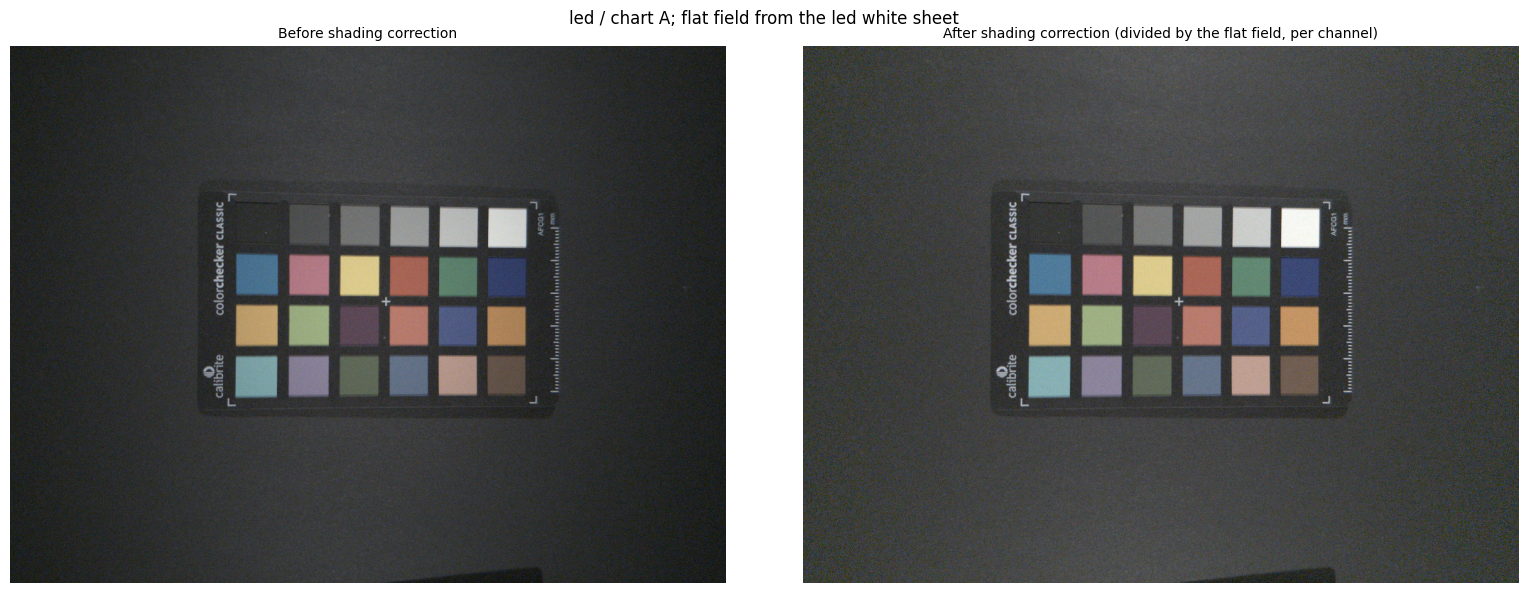

White sheet, led round: regions 5% of the short side, corners inset 2%


,corner,R corner/center,G corner/center,B corner/center
before,top left,0.336,0.349,0.352
before,top right,0.289,0.300,0.307
before,bottom left,0.315,0.326,0.333
before,bottom right,0.280,0.289,0.293
after,top left,1.000,0.998,0.997
after,top right,1.000,1.000,1.001
after,bottom left,0.999,0.998,1.001
after,bottom right,1.000,0.998,0.997


In [6]:
_FLAT = {}
def flat_field(rnd):
    """White sheet of FLAT_SOURCE[rnd], lightly smoothed (paper texture, noise), each channel
    normalized to its own center."""
    src = FLAT_SOURCE.get(rnd, rnd)
    if src not in _FLAT:
        white, _ = quarter_res(read_raw(capture_path(src, "white")), SAT_DN)
        sigma = FLAT_SMOOTH * white.shape[1]
        smooth = np.dstack([cv2.GaussianBlur(white[..., k], (0, 0), sigma) for k in range(3)])
        _FLAT[src] = smooth / region_means(smooth)["center"]
    return _FLAT[src]


def corrected(rnd, item):
    rgb, clip = quarter_res(read_raw(capture_path(rnd, item)), SAT_DN)
    return rgb / flat_field(rnd), clip


if (msg := missing((PRIMARY_ROUND, PRIMARY_CHART), (FLAT_SOURCE[PRIMARY_ROUND], "white"))):
    print(msg)
else:
    flat0 = flat_field(PRIMARY_ROUND)
    white0, _ = quarter_res(read_raw(capture_path(PRIMARY_ROUND, "white")), SAT_DN)
    rgb0_c, _ = corrected(PRIMARY_ROUND, PRIMARY_CHART)

    # Display both with the same per-channel scale: the white sheet's center, which also
    # neutralizes the illuminant for viewing.
    scale = region_means(white0)["center"] * 1.1
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    show_linear(axes[0], rgb0, scale, "Before shading correction")
    show_linear(axes[1], rgb0_c, scale, "After shading correction (divided by the flat field, per channel)")
    fig.suptitle(f"{PRIMARY_ROUND} / {PRIMARY_CHART}; flat field from the {FLAT_SOURCE[PRIMARY_ROUND]} white sheet")
    fig.tight_layout()
    plt.show()

    # Corner / center ratio on the white sheet itself, before and after
    rows = []
    for label, img in (("before", white0), ("after", white0 / flat0)):
        reg = region_means(img)
        for corner in ("top left", "top right", "bottom left", "bottom right"):
            rows.append({"": label, "corner": corner,
                         **{f"{c} corner/center": v for c, v in zip("RGB", reg[corner] / reg["center"])}})
    ratios = pd.DataFrame(rows)
    print(f"White sheet, {PRIMARY_ROUND} round: regions {REGION_FRAC:.0%} of the short side, "
          f"corners inset {CORNER_INSET:.0%}")
    display(ratios.style.hide(axis="index").format(precision=3))

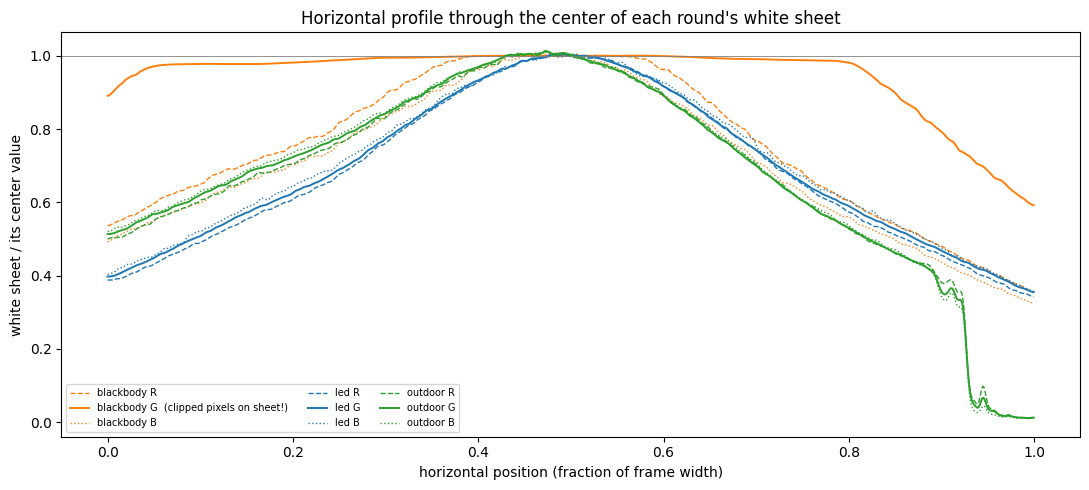

max |profile difference| blackbody vs led: R 0.169, G 0.527, B 0.098
max |profile difference| blackbody vs outdoor: R 0.380, G 0.666, B 0.362
max |profile difference| led vs outdoor: R 0.360, G 0.381, B 0.400


In [7]:
have_white = [r for r in ROUNDS if have(r, "white")]
if not have_white:
    print("No white-sheet captures yet.")
else:
    fig, ax = plt.subplots(figsize=(11, 5))
    colors = dict(zip(ROUNDS, ["tab:orange", "tab:blue", "tab:green", "tab:purple"]))
    profiles = {}
    for rnd in have_white:
        w, wclip = quarter_res(read_raw(capture_path(rnd, "white")), SAT_DN)
        w = w / region_means(w)["center"]
        h = w.shape[0]
        band = w[h // 2 - h // 100: h // 2 + h // 100 + 1].mean(axis=0)       # rows within ±1% of the center
        band = np.dstack([cv2.GaussianBlur(band[:, k][None, :], (0, 0), 5)[0] for k in range(3)])[0]
        profiles[rnd] = band
        x = np.arange(band.shape[0]) / band.shape[0]
        for k, (c, ls) in enumerate(zip("RGB", ("--", "-", ":"))):
            ax.plot(x, band[:, k], ls, color=colors[rnd], lw=1.4 if c == "G" else 1,
                    label=f"{rnd} {c}" + ("  (clipped pixels on sheet!)" if c == "G" and wclip.any() else ""))
    ax.axhline(1, color="gray", lw=0.6)
    ax.set_xlabel("horizontal position (fraction of frame width)")
    ax.set_ylabel("white sheet / its center value")
    ax.set_title("Horizontal profile through the center of each round's white sheet")
    ax.legend(fontsize=7, ncol=len(have_white))
    fig.tight_layout()
    plt.show()

    for a, b in combinations(have_white, 2):
        d = np.abs(profiles[a] - profiles[b]).max(axis=0)
        print(f"max |profile difference| {a} vs {b}: R {d[0]:.3f}, G {d[1]:.3f}, B {d[2]:.3f}")

#### How the shading percentages in the answer below are derived
1. **A shading map for each round.** Take the round's own white sheet, smooth it lightly and divide each channel by its value at the center of the frame, the same normalization as the profiles above. Call this S(x, y). It is 1.00 at the center, and 0.40 at a point that received 40% as much light as the center.
2. **Divide one round's map by another's.** The lens is the same in every round, so its falloff appears identically in both maps and cancels in the ratio S_A / S_B. Whatever is left is the difference in how evenly the two lights fell on the sheet. A ratio of 1.10 at a point means that, relative to its own center, round A received 10% more light there than round B did.
3. **Express it as a percentage and take its range.** 100 × (S_A / S_B − 1) is the percentage difference. Its minimum and maximum over the box that encloses all nine charts (the dashed box in the figure) are the two ends of each range. Only that box matters, because the patches are measured only there.
4. **Which channels.** Blackbody against LED uses the blue channel only, because the red and green channels of the blackbody sheet are clipped at its center, which would make its center normalization wrong. LED against outdoor uses all three channels, and the range quoted is the widest of the three.

If the lens were the only cause of the falloff, both ratio maps would be flat at 0%.

Box enclosing all nine charts: x 291-1484, y 421-1117 quarter-res px (14%-74% of the width, 28%-74% of the height)
Percentage difference 100 × (S_A / S_B − 1) over that box:


comparison,channel,min (%),5th pct (%),95th pct (%),max (%)
blackbody / led,B,-10.3,-6.7,10.5,14.6
led / outdoor,R,-18.4,-16.3,13.4,21.2
led / outdoor,G,-17.5,-15.6,14.7,23.8
led / outdoor,B,-16.4,-14.6,16.5,25.8


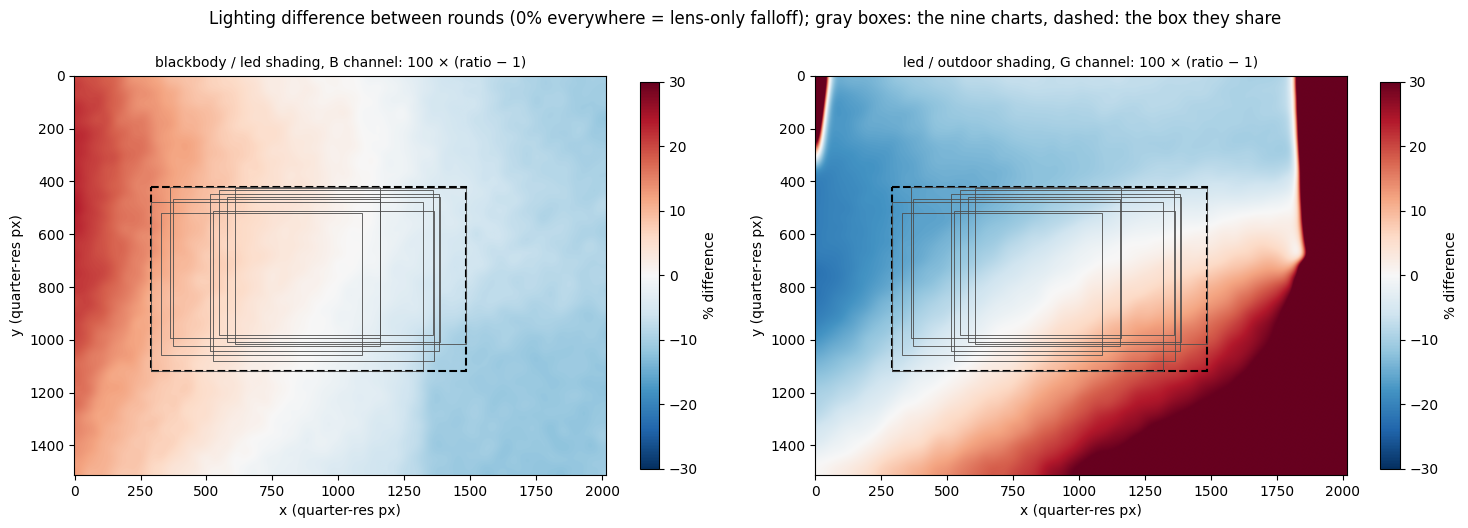

In [8]:
def own_shading(rnd):
    """A round's own white sheet, smoothed like the flat field and normalized to its center, per channel.
    (Unlike flat_field, this never borrows another round's sheet.)"""
    white, _ = quarter_res(read_raw(capture_path(rnd, "white")), SAT_DN)
    sigma = FLAT_SMOOTH * white.shape[1]
    smooth = np.dstack([cv2.GaussianBlur(white[..., k], (0, 0), sigma) for k in range(3)])
    return smooth / region_means(smooth)["center"]


def chart_box(rnd, chart):
    """Box (x0, x1, y0, y1) in quarter-res px around the patch grid of one capture: from CHART_CORNERS
    once entered, otherwise from the patch-shaped bright blobs found by thresholding the capture."""
    if CHART_CORNERS.get((rnd, chart)) is not None:
        c = np.asarray(CHART_CORNERS[(rnd, chart)], dtype=float)
        return c[:, 0].min(), c[:, 0].max(), c[:, 1].min(), c[:, 1].max()
    rgb, _ = quarter_res(read_raw(capture_path(rnd, chart)), SAT_DN)
    g = cv2.GaussianBlur(rgb[..., 1], (0, 0), 2)
    mask = (g > 0.25 * np.percentile(g, 99.5)).astype(np.uint8)
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    blobs = [s for s in stats[1:] if 3e-4 * g.size < s[4] < 1e-2 * g.size       # patch-sized
             and 0.6 < s[2] / s[3] < 1.6 and s[4] > 0.7 * s[2] * s[3]]          # square and solid
    x0 = min(s[0] for s in blobs); x1 = max(s[0] + s[2] for s in blobs)
    y0 = min(s[1] for s in blobs); y1 = max(s[1] + s[3] for s in blobs)
    pad = 0.25 * np.median([s[2] for s in blobs])                                  # reach the grid's outer edge
    return x0 - pad, x1 + pad, y0 - pad, y1 + pad


need = [(r, i) for r in ROUNDS for i in (*CHARTS, "white")]
if (msg := missing(*need)):
    print(msg)
else:
    S = {r: own_shading(r) for r in ROUNDS}
    boxes = {(r, c): chart_box(r, c) for r in ROUNDS for c in CHARTS}
    X0, Y0 = (int(np.floor(min(b[i] for b in boxes.values()))) for i in (0, 2))
    X1, Y1 = (int(np.ceil(max(b[i] for b in boxes.values()))) for i in (1, 3))
    h, w = S[ROUNDS[0]].shape[:2]
    print(f"Box enclosing all nine charts: x {X0}-{X1}, y {Y0}-{Y1} quarter-res px "
          f"({X0 / w:.0%}-{X1 / w:.0%} of the width, {Y0 / h:.0%}-{Y1 / h:.0%} of the height)")

    rows, maps = [], {}
    for a, b in (("blackbody", "led"), ("led", "outdoor")):
        for k, ch in enumerate("RGB"):
            if a == "blackbody" and ch != "B":
                continue                         # blackbody red and green are clipped at the sheet's center
            pct = 100 * (S[a][..., k] / S[b][..., k] - 1)
            maps[(a, b, ch)] = pct
            box = pct[Y0:Y1, X0:X1]
            rows.append({"comparison": f"{a} / {b}", "channel": ch, "min (%)": box.min(),
                         "5th pct (%)": np.percentile(box, 5), "95th pct (%)": np.percentile(box, 95),
                         "max (%)": box.max()})
    shading_diff = pd.DataFrame(rows)
    print("Percentage difference 100 × (S_A / S_B − 1) over that box:")
    display(shading_diff.style.hide(axis="index").format(precision=1))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    for ax, key in zip(axes, [("blackbody", "led", "B"), ("led", "outdoor", "G")]):
        im = ax.imshow(maps[key], cmap="RdBu_r", vmin=-30, vmax=30)
        ax.add_patch(plt.Rectangle((X0, Y0), X1 - X0, Y1 - Y0, fill=False, ls="--", lw=1.5, color="k"))
        for (r, c), (x0, x1, y0, y1) in boxes.items():
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=0.6, color="0.3"))
        ax.set_title(f"{key[0]} / {key[1]} shading, {key[2]} channel: 100 × (ratio − 1)", fontsize=10)
        ax.set_xlabel("x (quarter-res px)"); ax.set_ylabel("y (quarter-res px)")
        fig.colorbar(im, ax=ax, shrink=0.85, label="% difference")
    fig.suptitle("Lighting difference between rounds (0% everywhere = lens-only falloff); "
                 "gray boxes: the nine charts, dashed: the box they share")
    fig.tight_layout()
    plt.show()

### **What does the comparison of the rounds tell me?**
**Most of the falloff belongs to the lens, but not all of it: the lighting adds a different 10–25% unevenness in each round, so one round's flat field can only approximately stand in for another's. I therefore use each round's own white sheet wherever it is usable and borrow the LED flat field only for the blackbody round, whose sheet is clipped.**

**The falloff is steep:** before correction, the corners of the LED white sheet receive only 28–35% of the light at its center (corner/center ratio 0.280–0.352 across the four corners and three channels). After dividing by the flat field, every corner is within 0.3% of the center (0.997–1.001). Within a round, the red, green and blue profiles nearly coincide, so the falloff barely depends on color.

**What is common to every round (the lens):** every profile has the same shape, a single peak near the center of the frame falling to roughly 0.3–0.5 at the left and right edges. That shared shape is fixed to the frame rather than to the scene, so it belongs to the lens.

**What differs between rounds (the lighting):** the profiles do not lie on top of one another. On the left half of the frame, the blackbody and outdoor profiles agree with each other but sit about 10% above the LED profile. On the right half, the blackbody and LED profiles agree and the outdoor profile is lower. Across the box that encloses all nine charts, the blackbody shading (measured in its unclipped blue channel) differs from the LED shading by −10% to +15%, and the LED and outdoor shadings differ by −18% to +26% (the widest of the three channels; the cell above derives both ranges). A lens cannot produce differences that change from round to round, so this part comes from how evenly each light fell on the sheet.

**Reading the printed maximum differences:** the largest values (0.53 and 0.67 for blackbody green, and 0.36–0.40 for every comparison with the outdoor round) are not shading. The blackbody green profile is flat-topped because the center of that sheet is clipped, and the outdoor profile drops to near zero past about 90% of the frame width, where the sheet ends and the leaves begin.

**Consequence for the blackbody round:** its own sheet is clipped at the center, so it borrows the LED flat field (`FLAT_SOURCE`). That removes the lens part of the falloff but    leaves up to about 10–15% of uncorrected lighting unevenness across the chart, which will add some error to the blackbody results in item 11.

### Problem 4: Locate the twenty four patches and extract their mean linear RGB. Sample well inside each patch, no more than the middle half of it, so that the black separators and any edge artifacts stay out of the average.
_Deliverable: A figure showing the regions you sampled drawn on the chart, and your 24 by 3 table of patch means._

_Locating the chart:_ enter the four outer corners of the patch grid for each chart capture in `CHART_CORNERS` (setup cell), in quarter-resolution pixels, in the order: the corner next to patch 1 (dark skin), next to patch 6 (bluish green), next to patch 24 (black), next to patch 19 (white). A homography maps the 6 × 4 grid into the image, so a chart that is tilted, rotated or seen in perspective is sampled correctly. For a capture with no corners entered, the cell below draws it with a coordinate grid to read them from.

Enter CHART_CORNERS[('led', 'chart A')] (setup cell), then re-run from here.


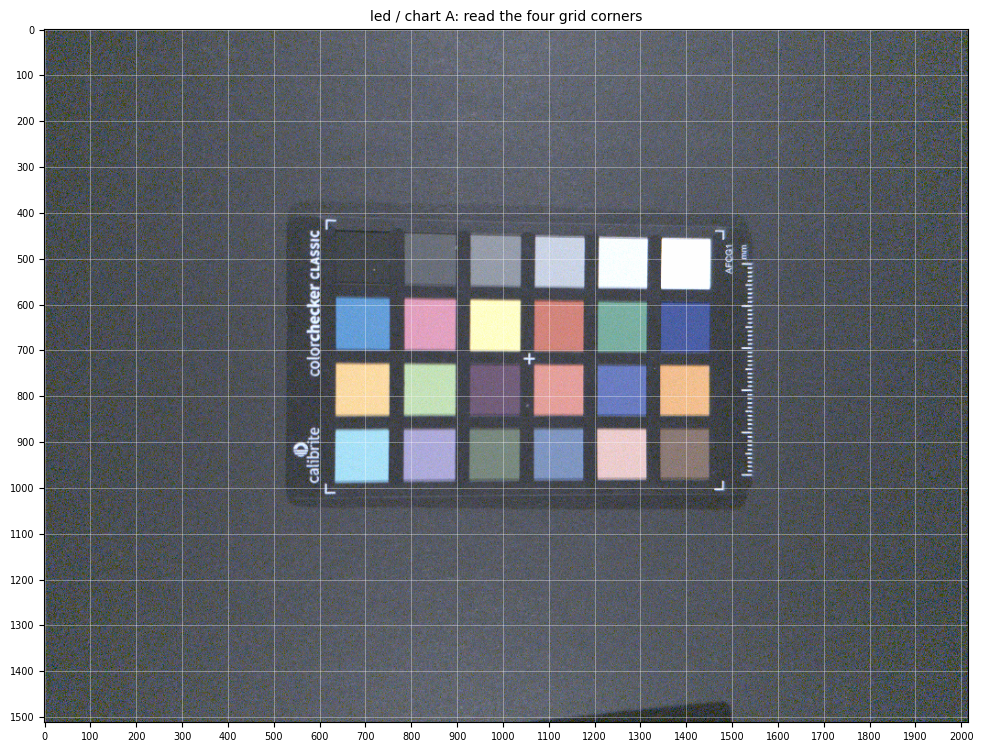

In [20]:
REF = colour.CCS_COLOURCHECKERS[REFERENCE_SET]
PATCH_NAMES = list(REF.data.keys())
CHART_UNIT_CORNERS = np.float32([[0, 0], [6, 0], [6, 4], [0, 4]])   # dark skin, bluish green, black, white


def patch_polygons(corners, frac=SAMPLE_FRACTION):
    """The sampled square of each patch, mapped into the image. Patch k (0-23) is row k // 6, column k % 6."""
    H = cv2.getPerspectiveTransform(CHART_UNIT_CORNERS, np.float32(corners))
    polys = []
    for k in range(24):
        r, c = divmod(k, 6)
        cx, cy, h = c + 0.5, r + 0.5, frac / 2
        sq = np.float32([[cx - h, cy - h], [cx + h, cy - h], [cx + h, cy + h], [cx - h, cy + h]])
        polys.append(cv2.perspectiveTransform(sq[None], H)[0])
    return polys


_PATCHES = {}
def patches(rnd, chart):
    """24-row table of mean linear RGB (shading-corrected) in reference order, with clipping flags."""
    if (rnd, chart) not in _PATCHES:
        rgb, clip = corrected(rnd, chart)
        rows = []
        for k, poly in enumerate(patch_polygons(CHART_CORNERS[(rnd, chart)])):
            x0, y0 = np.floor(poly.min(axis=0)).astype(int)
            x1, y1 = np.ceil(poly.max(axis=0)).astype(int) + 1
            mask = np.zeros((y1 - y0, x1 - x0), np.uint8)
            cv2.fillConvexPoly(mask, np.round(poly - [x0, y0]).astype(np.int32), 1)
            m = mask.astype(bool)
            vals = rgb[y0:y1, x0:x1][m]
            rows.append({"patch": k + 1, "name": PATCH_NAMES[k],
                         "R": float(vals[:, 0].mean()), "G": float(vals[:, 1].mean()), "B": float(vals[:, 2].mean()),
                         "G rel. s.d.": vals[:, 1].std() / vals[:, 1].mean(),
                         "clipped px": int(clip[y0:y1, x0:x1][m].sum()), "n px": int(m.sum())})
        df = pd.DataFrame(rows).set_index("patch")
        df["clipped"] = df["clipped px"] > 0
        _PATCHES[(rnd, chart)] = df
    return _PATCHES[(rnd, chart)]


def corner_helper(rnd, chart):
    """Show a capture with a coordinate grid so the patch-grid corners can be read off."""
    rgb, _ = corrected(rnd, chart)
    fig, ax = plt.subplots(figsize=(12, 9))
    show_linear(ax, rgb, np.percentile(rgb, 99, axis=(0, 1)), f"{rnd} / {chart}: read the four grid corners")
    ax.axis("on")
    ax.set_xticks(np.arange(0, rgb.shape[1], 100)); ax.set_yticks(np.arange(0, rgb.shape[0], 100))
    ax.tick_params(labelsize=7); ax.grid(color="w", lw=0.4, alpha=0.6)
    plt.show()


def draw_patches(ax, rnd, chart):
    rgb, _ = corrected(rnd, chart)
    df = patches(rnd, chart)
    show_linear(ax, rgb, np.percentile(rgb, 99, axis=(0, 1)), f"{rnd} / {chart}", step=1)
    polys = patch_polygons(CHART_CORNERS[(rnd, chart)])
    for k, poly in enumerate(polys):
        bad = df.clipped.iloc[k]
        outline = [pe.Stroke(linewidth=2.6, foreground="black"), pe.Normal()]
        ax.add_patch(Polygon(poly, closed=True, fill=False, lw=1.2, edgecolor="red" if bad else "yellow",
                             path_effects=outline))
        ax.text(*poly.mean(axis=0), str(k + 1), color="red" if bad else "yellow",
                ha="center", va="center", fontsize=7, path_effects=outline)
    allp = np.concatenate(polys)
    pad = 0.15 * np.ptp(allp, axis=0).max()
    ax.set_xlim(allp[:, 0].min() - pad, allp[:, 0].max() + pad)
    ax.set_ylim(allp[:, 1].max() + pad, allp[:, 1].min() - pad)


key0 = (PRIMARY_ROUND, PRIMARY_CHART)
if (msg := missing(key0, (FLAT_SOURCE[PRIMARY_ROUND], "white"))):
    print(msg)
elif CHART_CORNERS[key0] is None:
    print(f"Enter CHART_CORNERS[{key0}] (setup cell), then re-run from here.")
    corner_helper(*key0)
else:
    fig, ax = plt.subplots(figsize=(10, 7.5))
    draw_patches(ax, *key0)
    ax.set_title(f"{PRIMARY_ROUND} / {PRIMARY_CHART}: sampled regions "
                 f"({SAMPLE_FRACTION:.0%} of the patch pitch; red = contains clipped pixels)")
    plt.show()
    pm0 = patches(*key0)
    print(f"Clipped patches: {list(pm0.index[pm0.clipped]) or 'none'}")
    display(pm0[["name", "R", "G", "B", "G rel. s.d.", "clipped"]].style.format(
        {"R": "{:.4f}", "G": "{:.4f}", "B": "{:.4f}", "G rel. s.d.": "{:.3f}"}))

In [10]:
# The other chart captures: corners still to enter, and a check of every chart that has them
todo = [k for k, v in CHART_CORNERS.items() if v is None and have(*k)]
done = [k for k, v in CHART_CORNERS.items() if v is not None and have(*k) and have(FLAT_SOURCE[k[0]], "white")]
if todo:
    print("Corners still to enter for:", ", ".join(f"{r} / {c}" for r, c in todo))
    print("Run corner_helper(round, chart) in a scratch cell to read them.")
if done:
    ncols = min(3, len(done))
    nrows = int(np.ceil(len(done) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.2 * nrows), squeeze=False)
    for ax, k in zip(axes.flat, done):
        draw_patches(ax, *k)
    for ax in axes.flat[len(done):]:
        ax.axis("off")
    fig.suptitle("Sampled regions on every chart capture (red = contains clipped pixels)")
    fig.tight_layout()
    plt.show()

Corners still to enter for: blackbody / chart A, blackbody / chart B, blackbody / chart C, led / chart A, led / chart B, led / chart C, outdoor / chart A, outdoor / chart B, outdoor / chart C
Run corner_helper(round, chart) in a scratch cell to read them.


## Part 2: White Balance and the Color Matrix

Let c be the measured linear camera RGB of a patch and t its published tristimulus value. The reference data is the ColorChecker24 set in the colour-science package, `colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]`, converted from xyY to XYZ. A measured neutral patch is the reference white for every conversion to CIELAB, so that the measurement and the reference are compared under the same white point: patch 19 (white), or the brightest unclipped neutral if it has clipped. ΔE is CIEDE2000 throughout.

_How the white point is applied here (`LAB_WHITE = "reference"`):_ the measured XYZ is scaled so that the reference neutral has its published luminance, and both the measurement and the reference are converted to CIELAB with that patch's published XYZ as the white. Setting `LAB_WHITE = "own"` instead gives the measurement its own measured neutral as white.

In [11]:
REF_XYZ = colour.xyY_to_XYZ(np.array(list(REF.data.values())))
SRGB_TO_XYZ = colour.RGB_COLOURSPACES["sRGB"].matrix_RGB_to_XYZ
print(f"Reference: {REFERENCE_SET}, {len(PATCH_NAMES)} patches, measured under illuminant xy {REF.illuminant}")
print(f"Patch 1 is '{PATCH_NAMES[0]}', patch 19 is '{PATCH_NAMES[18]}', patch {GAIN_PATCH} is '{PATCH_NAMES[GAIN_PATCH - 1]}'")


def check_orientation(rgb):
    """Problems with the patch numbering, judged from the 24 x 3 camera means (empty list = consistent).
    Neutrals 20-23 must darken in order and share one chromaticity; red (15) and blue (13) must
    stand out from them in R and B. A rotated or mirrored chart fails these."""
    problems = []
    g = rgb[18:24, 1]
    if not np.all(np.diff(g[1:]) < 0):
        problems.append("patches 20-24 do not darken in order")
    ratio = rgb[19:23][:, [0, 2]] / rgb[19:23, 1:2]                 # R/G and B/G of neutrals 20-23
    spread = ratio.std(axis=0) / ratio.mean(axis=0)
    if np.any(spread > 0.08):
        problems.append(f"patches 20-23 are not one neutral (R/G, B/G spread {spread.round(3).tolist()})")
    neutral = ratio.mean(axis=0)
    if rgb[14, 0] / rgb[14, 1] / neutral[0] < 1.5:
        problems.append("patch 15 is not red")
    if rgb[12, 2] / rgb[12, 1] / neutral[1] < 1.5:
        problems.append("patch 13 is not blue")
    return problems


def wb_gains(rgb, patch=GAIN_PATCH):
    """Gains, normalized to green, that make the gain patch neutral (equal camera RGB)."""
    p = rgb[patch - 1]
    return p[1] / p


def reference_white(clipped):
    """Index (0-based) of the neutral used as the CIELAB white: white, else the brightest unclipped neutral."""
    for k in [WHITE_PATCH - 1] + [k for k in range(18, 22) if k != WHITE_PATCH - 1]:
        if not clipped[k]:
            return k
    raise RuntimeError("Every bright neutral has clipped.")


def to_lab(xyz, white_xyz):
    return colour.XYZ_to_Lab(np.asarray(xyz) / white_xyz[1], colour.XYZ_to_xy(white_xyz))


def delta_e(xyz_meas, wk):
    """Per-patch ΔE (DE_METHOD) of measured XYZ against the reference, with patch wk as the white.
    The measurement is first scaled so that patch wk has its published luminance."""
    xyz = np.asarray(xyz_meas) * (REF_XYZ[wk, 1] / xyz_meas[wk, 1])
    white_meas = REF_XYZ[wk] if LAB_WHITE == "reference" else xyz[wk]
    return colour.delta_E(to_lab(xyz, white_meas), to_lab(REF_XYZ, REF_XYZ[wk]), method=DE_METHOD)


def fit_ccm(c, t, use):
    """3 x 3 M minimizing sum ||M c - t||^2 over the patches in `use`."""
    X, *_ = np.linalg.lstsq(c[use], t[use], rcond=None)
    return X.T


def analyze(rnd, chart, M=None):
    """Items 5-8 for one capture. With M given, the white balance is refitted but the matrix is not."""
    df = patches(rnd, chart)
    rgb = df[["R", "G", "B"]].to_numpy(dtype=float)
    clipped = df.clipped.to_numpy()
    problems = check_orientation(rgb)
    assert not problems, f"{rnd} / {chart}: patch numbering does not match the reference: {problems}"
    assert not clipped[GAIN_PATCH - 1], f"{rnd} / {chart}: the gain patch {GAIN_PATCH} has clipped"
    gains = wb_gains(rgb)
    c = rgb * gains
    wk = reference_white(clipped)
    use = ~clipped
    if M is None:
        M = fit_ccm(c, REF_XYZ, use)
    de_before = np.where(use, delta_e(c @ SRGB_TO_XYZ.T, wk), np.nan)
    de_after = np.where(use, delta_e(c @ M.T, wk), np.nan)
    return {"round": rnd, "chart": chart, "gains": gains, "balanced": c, "white_k": wk, "clipped": clipped,
            "M": M, "de_before": de_before, "de_after": de_after}


def fmt_gains(g):
    return ", ".join(f"{float(v):.4f}" for v in g)


def summary(de):
    k = int(np.nanargmax(de))
    return {"mean": float(np.nanmean(de)), "worst": float(de[k]), "worst patch": f"{k + 1} {PATCH_NAMES[k]}"}


ready0 = not missing(key0, (FLAT_SOURCE[PRIMARY_ROUND], "white")) and CHART_CORNERS[key0] is not None

Reference: ColorChecker24 - After November 2014, 24 patches, measured under illuminant xy [ 0.34570291  0.3585386 ]
Patch 1 is 'dark skin', patch 19 is 'white 9.5 (.05 D)', patch 22 is 'neutral 5 (.70 D)'


### Problem 5: Fit the white balance gains from the neutral patches, which are patches 19 through 24 of the reference set, and apply them to all twenty four. Before you do, confirm that your patch numbering matches that set, whose first patch is dark skin and whose nineteenth is white. Set the gains from an unclipped mid gray patch rather than from the white one. A neutral surface should produce equal camera RGB, and the gains are whatever makes that true.
_Deliverable: The three gains, normalized to the green channel, and the patch means after balancing._

In [12]:
if not ready0:
    print("Item 4 is not complete for the primary capture yet.")
else:
    rgb_p = patches(*key0)[["R", "G", "B"]].to_numpy()
    problems = check_orientation(rgb_p)
    print("Patch numbering check:", "matches the reference set (patch 1 dark skin, 19 white)"
          if not problems else f"FAILED: {problems}")
    A = analyze(*key0)
    print(f"White balance from patch {GAIN_PATCH} ({PATCH_NAMES[GAIN_PATCH - 1]}): "
          f"gains R {A['gains'][0]:.4f}, G {A['gains'][1]:.4f}, B {A['gains'][2]:.4f}")
    bal = pd.DataFrame(A["balanced"], columns=["R", "G", "B"], index=pd.Index(range(1, 25), name="patch"))
    bal.insert(0, "name", PATCH_NAMES)
    bal["clipped"] = A["clipped"]
    bal["B/G"], bal["R/G"] = bal.B / bal.G, bal.R / bal.G
    print("Neutrals after balancing (R/G and B/G should be close to 1):")
    display(bal.loc[19:24, ["name", "R/G", "B/G"]].style.format(precision=3))
    display(bal[["name", "R", "G", "B", "clipped"]].style.format(precision=4))

Item 4 is not complete for the primary capture yet.


### Problem 6: Report the error before any matrix is fitted, by treating your white balanced camera RGB as though it were linear sRGB and converting it to XYZ with the standard sRGB primaries.
_Deliverable: Mean and worst ΔE across the twenty four patches, and the name of the metric._

In [13]:
if not ready0:
    print("Item 4 is not complete for the primary capture yet.")
else:
    s = summary(A["de_before"])
    print(f"White balanced camera RGB treated as linear sRGB, {PRIMARY_ROUND} / {PRIMARY_CHART}:")
    print(f"  mean ΔE ({DE_METHOD}) = {s['mean']:.2f}, worst = {s['worst']:.2f} (patch {s['worst patch']})")
    print(f"  CIELAB white: patch {A['white_k'] + 1} ({PATCH_NAMES[A['white_k']]}); "
          f"{int(A['clipped'].sum())} clipped patch(es) excluded")

Item 4 is not complete for the primary capture yet.


### Problem 7: Fit the three by three matrix that best maps your white balanced camera RGB to the reference XYZ in a least squares sense across all twenty four patches.
_Deliverable: The matrix, and one sentence on whether its rows sum to something close to preserving a neutral._

In [14]:
if not ready0:
    print("Item 4 is not complete for the primary capture yet.")
else:
    M = A["M"]
    print(f"Color correction matrix, white balanced camera RGB -> XYZ ({PRIMARY_ROUND} / {PRIMARY_CHART}, "
          f"{int((~A['clipped']).sum())} patches):")
    display(pd.DataFrame(M, index=["X", "Y", "Z"], columns=["R", "G", "B"]).style.format("{:.4f}"))

    # A balanced neutral has R = G = B, so M maps it to the row sums. Preserving a neutral means
    # the row sums point in the direction of the reference white.
    rs = M.sum(axis=1)
    wref = REF_XYZ[A["white_k"]]
    print(f"Row sums (XYZ of R = G = B = 1): {rs.round(4).tolist()}")
    print(f"  chromaticity xy {colour.XYZ_to_xy(rs).round(4).tolist()} vs reference neutral "
          f"(patch {A['white_k'] + 1}) xy {colour.XYZ_to_xy(wref).round(4).tolist()}")
    print(f"  row sums / reference neutral XYZ, scaled to Y: {(rs / rs[1] / (wref / wref[1])).round(4).tolist()}")

Item 4 is not complete for the primary capture yet.


### **Do the matrix's rows preserve a neutral?**
_To be written after running the cells above._

### Problem 8: Apply the matrix and report the error again. Identify which patches remain the worst, and explain in three or four sentences why the residual does not fall to zero no matter how good the fit is.
_Deliverable: A figure of per patch ΔE before and after, the mean and worst value for each, the names of the two or three worst patches, and your written explanation._

In [15]:
if not ready0:
    print("Item 4 is not complete for the primary capture yet.")
else:
    sb, sa = summary(A["de_before"]), summary(A["de_after"])
    print(f"ΔE ({DE_METHOD}), {PRIMARY_ROUND} / {PRIMARY_CHART}:")
    print(f"  before matrix (sRGB primaries): mean {sb['mean']:.2f}, worst {sb['worst']:.2f} ({sb['worst patch']})")
    print(f"  after matrix:                   mean {sa['mean']:.2f}, worst {sa['worst']:.2f} ({sa['worst patch']})")
    order = np.argsort(-np.nan_to_num(A["de_after"], nan=-1))
    print("  worst three after the matrix: " +
          ", ".join(f"{k + 1} {PATCH_NAMES[k]} ({A['de_after'][k]:.2f})" for k in order[:3]))

    x = np.arange(1, 25)
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.bar(x - 0.2, A["de_before"], 0.4, label=f"before (sRGB primaries): mean {sb['mean']:.2f}")
    ax.bar(x + 0.2, A["de_after"], 0.4, label=f"after (fitted matrix): mean {sa['mean']:.2f}")
    for k in np.nonzero(A["clipped"])[0]:
        ax.text(k + 1, 0, "clipped", rotation=90, ha="center", va="bottom", fontsize=7, color="tab:red")
    ax.set_xticks(x, [f"{k} {n}" for k, n in zip(x, PATCH_NAMES)], rotation=60, ha="right", fontsize=8)
    ax.set_ylabel(f"ΔE ({DE_METHOD})")
    ax.set_title(f"Per-patch error, {PRIMARY_ROUND} / {PRIMARY_CHART}")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Item 4 is not complete for the primary capture yet.


### **Why does the residual not fall to zero?**
_To be written after running the cells above._

## Part 3: How Much of This Belongs to the Chart?

Three nominally identical charts were photographed under the same light with the same camera, so any disagreement between them is a property of the charts and of the measurement procedure rather than of the sensor.

### Problem 9: Repeat items 5 through 8 independently for all three charts photographed under one illuminant of your choosing, and report the three mean ΔE values and the three matrices. Keep track of which chart is which.
_Deliverable: Three mean and three worst ΔE values, and a comment on whether the three matrices resemble one another. Compare their columns as directions rather than element by element._

In [16]:
p3_keys = [(PART3_ROUND, c) for c in CHARTS]
p3_ready = [k for k in p3_keys if have(*k) and CHART_CORNERS[k] is not None and have(FLAT_SOURCE[k[0]], "white")]
if len(p3_ready) < 3:
    print(f"Item 9 needs all three charts of the {PART3_ROUND} round with corners entered; "
          f"ready: {[c for _, c in p3_ready]}")
else:
    p3 = {c: analyze(PART3_ROUND, c) for _, c in p3_keys}
    rows = []
    for c, a in p3.items():
        sb, sa = summary(a["de_before"]), summary(a["de_after"])
        rows.append({"chart": c, "file": capture_path(PART3_ROUND, c).name,
                     "mean ΔE before": sb["mean"], "worst before": sb["worst"],
                     "mean ΔE after": sa["mean"], "worst after": sa["worst"], "worst patch after": sa["worst patch"],
                     "gains (R, G, B)": fmt_gains(a["gains"])})
    p3_table = pd.DataFrame(rows)
    print(f"{PART3_ROUND} round, ΔE metric {DE_METHOD}:")
    display(p3_table.style.hide(axis="index").format(precision=2))
    for c, a in p3.items():
        print(f"\n{c} matrix (rows X, Y, Z; columns R, G, B):")
        print(np.array2string(a["M"], precision=4, suppress_small=True))

    # Columns as directions: the angle between corresponding columns, and the ratio of their lengths
    rows = []
    for j, col in enumerate("RGB"):
        for a, b in combinations(CHARTS, 2):
            u, v = p3[a]["M"][:, j], p3[b]["M"][:, j]
            ang = np.degrees(np.arccos(np.clip(u @ v / np.linalg.norm(u) / np.linalg.norm(v), -1, 1)))
            rows.append({"column": col, "pair": f"{a} vs {b}", "angle (deg)": ang,
                         "length ratio": np.linalg.norm(u) / np.linalg.norm(v)})
    print("\nMatrix columns compared as directions:")
    display(pd.DataFrame(rows).style.hide(axis="index").format({"angle (deg)": "{:.2f}", "length ratio": "{:.4f}"}))

Item 9 needs all three charts of the led round with corners entered; ready: []


### **Do the three matrices resemble one another?**
_To be written after running the cells above._

### Problem 10: Use the spread across those three charts as the uncertainty on your color accuracy, and record your results. If the three agree closely, say so: that is a result about the charts, not a failed measurement.
_Deliverable: Your mean ΔE after correction as a value with an uncertainty, and the five color entries of your Project 1 results.json, which are the metric, the reference set, the mean ΔE before and after correction, and the worst patch after correction._

In [17]:
if len(p3_ready) < 3:
    print("Item 9 is not complete yet.")
else:
    after = p3_table["mean ΔE after"].to_numpy()
    before = p3_table["mean ΔE before"].to_numpy()
    print(f"Mean ΔE ({DE_METHOD}) after correction, {PART3_ROUND} round, three charts: "
          f"{after.mean():.2f} ± {after.std(ddof=1):.2f} (mean ± s.d.; range {after.min():.2f} to {after.max():.2f})")
    print(f"Mean ΔE before correction: {before.mean():.2f} ± {before.std(ddof=1):.2f}")

    # Worst patch after correction: the patch with the largest ΔE averaged over the three charts
    de_after_all = np.vstack([p3[c]["de_after"] for c in CHARTS])
    kw = int(np.nanargmax(np.nanmean(de_after_all, axis=0)))

    # The five color entries for Project 1. Rename the keys to match the results.json schema on
    # the Project 1 page before copying them across.
    color_results = {
        "color_metric": f"CIEDE2000 ({DE_METHOD} in colour-science)",
        "color_reference": f"colour.CCS_COLOURCHECKERS['{REFERENCE_SET}']",
        "color_mean_dE_before": round(float(before.mean()), 2),
        "color_mean_dE_after": round(float(after.mean()), 2),
        "color_worst_patch_after": f"{kw + 1} {PATCH_NAMES[kw]} (ΔE {np.nanmean(de_after_all[:, kw]):.2f})",
    }
    RESULTS_FILE.write_text(json.dumps(color_results, indent=2, ensure_ascii=False))
    print(f"\nWritten to {RESULTS_FILE}:")
    print(json.dumps(color_results, indent=2, ensure_ascii=False))

Item 9 is not complete yet.


### **My color accuracy, with its uncertainty**
_To be written after running the cells above._

## Part 4: How Much of It Belongs to the Illuminant?

Two of the illuminants have similar color temperatures and very different spectra (a smooth blackbody curve, and a narrow blue peak with a phosphor hump); the third differs in color temperature while keeping a smooth spectrum. A matrix fitted under one and carried to another tests the claim in lecture 6 that the camera is a different observer from the eye.

### Problem 11: Take the matrix you fitted in item 7, apply it unchanged to the same chart photographed under the second illuminant, and report the error. Refit the white balance gains for the new illuminant, but do not refit the matrix. Then scale the balanced values so that your reference neutral matches its published value before you compute ΔE.
_Deliverable: Mean and worst ΔE under the second illuminant, beside the values you obtained under the first._

In [18]:
def transfer(rnd):
    """Item 7's matrix carried unchanged to `rnd` (gains refitted), with a refitted matrix for comparison."""
    k = (rnd, PRIMARY_CHART)
    if missing(k, (FLAT_SOURCE[rnd], "white")) or CHART_CORNERS[k] is None:
        return None
    return {"carried": analyze(rnd, PRIMARY_CHART, M=A["M"]), "refit": analyze(rnd, PRIMARY_CHART)}


def transfer_row(label, carried, refit=None):
    s = summary(carried["de_after"])
    row = {"illuminant": label, "mean ΔE": s["mean"], "worst ΔE": s["worst"], "worst patch": s["worst patch"],
           "gains (R, G, B)": fmt_gains(carried["gains"])}
    if refit is not None:
        row["mean ΔE, matrix refitted (reference only)"] = summary(refit["de_after"])["mean"]
    return row


if not ready0:
    print("Items 4-8 are not complete for the primary capture yet.")
else:
    T = {TRANSFER_ROUNDS[0]: transfer(TRANSFER_ROUNDS[0])}
    if T[TRANSFER_ROUNDS[0]] is None:
        print(f"No usable {TRANSFER_ROUNDS[0]} / {PRIMARY_CHART} capture with corners yet.")
    else:
        rows = [transfer_row(f"{PRIMARY_ROUND} (matrix fitted here)", A, A),
                transfer_row(f"{TRANSFER_ROUNDS[0]} (matrix carried over)", **T[TRANSFER_ROUNDS[0]])]
        print(f"{PRIMARY_CHART}, ΔE metric {DE_METHOD}; reference neutral scaled to its published value:")
        display(pd.DataFrame(rows).style.hide(axis="index").format(precision=2))

Items 4-8 are not complete for the primary capture yet.


### Problem 12: Do the same for the third illuminant.
_Deliverable: Mean and worst ΔE under the third illuminant, and a single figure comparing per patch ΔE across all three._

In [19]:
if not ready0:
    print("Items 4-8 are not complete for the primary capture yet.")
else:
    T[TRANSFER_ROUNDS[1]] = transfer(TRANSFER_ROUNDS[1])
    avail = [r for r in TRANSFER_ROUNDS if T.get(r) is not None]
    if TRANSFER_ROUNDS[1] not in avail:
        print(f"No usable {TRANSFER_ROUNDS[1]} / {PRIMARY_CHART} capture with corners yet.")
    rows = [transfer_row(f"{PRIMARY_ROUND} (matrix fitted here)", A, A)]
    rows += [transfer_row(f"{r} (matrix carried over)", **T[r]) for r in avail]
    print(f"{PRIMARY_CHART}, ΔE metric {DE_METHOD}; matrix from item 7 in every row:")
    display(pd.DataFrame(rows).style.hide(axis="index").format(precision=2))

    series = [(f"{PRIMARY_ROUND} (fitted)", A["de_after"])] + [(f"{r} (carried)", T[r]["carried"]["de_after"]) for r in avail]
    x = np.arange(1, 25)
    wbar = 0.8 / len(series)
    fig, ax = plt.subplots(figsize=(14, 4.8))
    for i, (label, de) in enumerate(series):
        ax.bar(x + (i - (len(series) - 1) / 2) * wbar, de, wbar, label=f"{label}: mean {np.nanmean(de):.2f}")
    ax.set_xticks(x, [f"{k} {n}" for k, n in zip(x, PATCH_NAMES)], rotation=60, ha="right", fontsize=8)
    ax.set_ylabel(f"ΔE ({DE_METHOD})")
    ax.set_title(f"Per-patch error with the {PRIMARY_ROUND} matrix under each illuminant ({PRIMARY_CHART})")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Items 4-8 are not complete for the primary capture yet.


### Problem 13: Interpret the comparison. State which transfer degraded more, say whether the degradation tracks the change in color temperature or the change in spectral shape, and explain what that implies about whether a single matrix stored in a camera can be correct under every light.
_Deliverable: A written analysis, four to six sentences, referring to your own numbers._

### **Which transfer degraded more, and why?**
_To be written after running the cells above._

## Part 5: Reflections
### Problem 14: What did you learn from this assignment?
_Deliverable: A brief written response._

_To be written after running the cells above._

### Problem 15: What questions, if any, do you have for me after completing this assignment?
_Deliverable: A brief written response._

_To be written after running the cells above._